# CSCIE89 : CNN - Multi Class Classification : Five Flower Categories

We will train a small convolutional neural network **from scratch** on real color photographs. No pretrained weights are used, that will be discussed next week in the class. 

We will download images, inspect labels, create separate training/validation/test sets, resize images, build a classification CNN, train it, and evaluate predictions. Unlike the previous 8×8 digits example, these images have three color channels and varied backgrounds, so the task is harder.

The first run needs internet access and disk space for the downloaded images. Or you can download ahead of time.

Downloads are reused on subsequent runs. Training time depends on your computer; a GPU will help. 

The default is 15 epochs and 64×64 images to keep this manageable.  

We will do 50 epochs and also make a point around why its important to keep an eye on the Validataion and Test loss.

## 1. Install packages and import tools

If the imports fail, uncomment the installation line, run it once, then restart the kernel. TensorFlow is not required, even for the Flower Photos dataset.

In [23]:
# %pip install torch torchvision scikit-learn matplotlib pillow

from pathlib import Path
import copy
import json
import random
import time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from torchvision.datasets.utils import download_and_extract_archive
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    ConfusionMatrixDisplay,
)

# Seeds make the split and initial weights repeatable, but do not guarantee
# identical floating-point results across all devices or PyTorch versions.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)  # Avoid excessive CPU thread overhead on this small model.
device = torch.device('cuda' if torch.cuda.is_available() else
                      'mps' if torch.backends.mps.is_available() else 'cpu')
IMAGE_SIZE = 64
BATCH_SIZE = 64
EPOCHS = 15
LEARNING_RATE = 0.001
DATA_DIR = Path('../data')
DATA_DIR.mkdir(exist_ok=True)
print('PyTorch:', torch.__version__, '| Device:', device)

PyTorch: 2.14.0 | Device: mps


## 2. Download Flower Photos and read the labels

The [Flower Photos dataset](https://www.tensorflow.org/tutorials/images/classification) has 3,670 photographs in five folders: daisy, dandelion, roses, sunflowers, and tulips. The archive is approximately 220 MB. 

`ImageFolder` daisy, roses etc -assigns labels from alphabetically sorted folder names. We read that mapping instead of guessing the numbers. This dataset has no official test split, so we will make a reproducible stratified 70%/15%/15% split.

In [24]:
flower_root = DATA_DIR / 'flower_photos'
if not flower_root.exists():
    download_and_extract_archive(
        'https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz',
        download_root=str(DATA_DIR),
    )
catalog = datasets.ImageFolder(flower_root)
class_names = catalog.classes
# Each record is (path_to_image, integer_class_label).
records = [(Path(path), label) for path, label in catalog.samples]
labels = [label for _, label in records]
train_records, remaining = train_test_split(
    records, test_size=0.30, random_state=SEED, stratify=labels)
val_records, test_records = train_test_split(
    remaining, test_size=0.50, random_state=SEED,
    stratify=[label for _, label in remaining])
print('Folder-to-label mapping:', catalog.class_to_idx)

Folder-to-label mapping: {'daisy': 0, 'dandelion': 1, 'roses': 2, 'sunflowers': 3, 'tulips': 4}


## 3. Check the split and look at real images

Training images teach the weights. Validation images select the best epoch. Test images are reserved for final evaluation, after those decisions. Never adjust settings based on test results; use validation results for experiments.

Train: 2569 images | {'daisy': 443, 'dandelion': 629, 'roses': 449, 'sunflowers': 489, 'tulips': 559}
Validation: 550 images | {'daisy': 95, 'dandelion': 134, 'roses': 96, 'sunflowers': 105, 'tulips': 120}
Test: 551 images | {'daisy': 95, 'dandelion': 135, 'roses': 96, 'sunflowers': 105, 'tulips': 120}


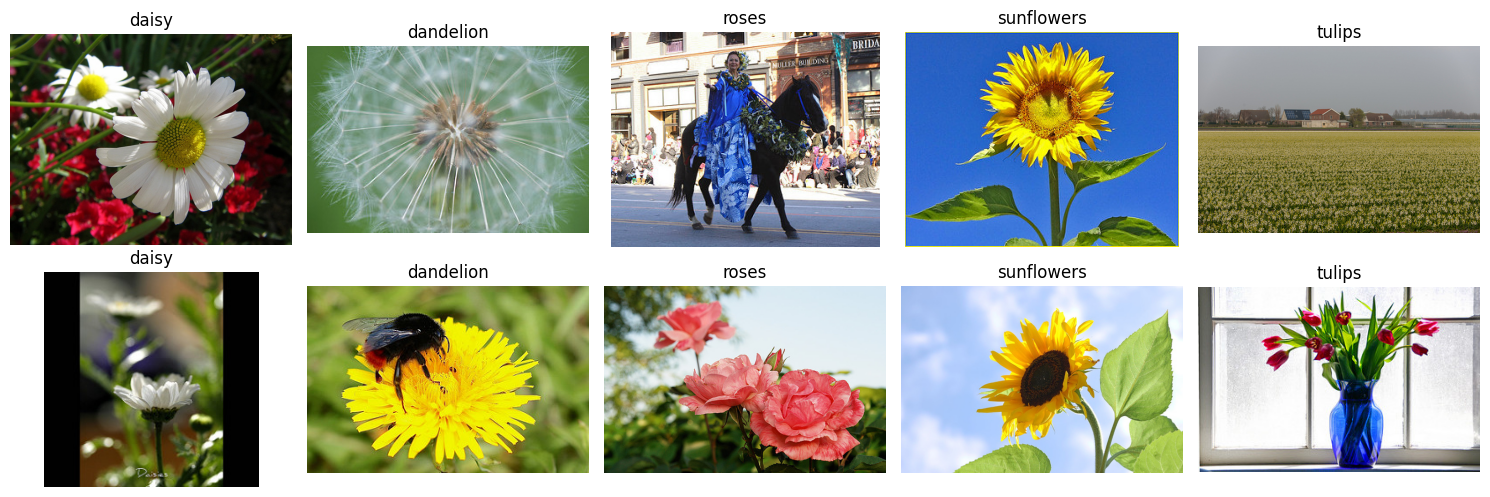

In [25]:
# A path must appear in only one split: this checks for accidental overlap.
train_paths = {path for path, _ in train_records}
val_paths = {path for path, _ in val_records}
test_paths = {path for path, _ in test_records}
assert train_paths.isdisjoint(val_paths)
assert train_paths.isdisjoint(test_paths)
assert val_paths.isdisjoint(test_paths)
for name, records in [('Train', train_records), ('Validation', val_records), ('Test', test_records)]:
    counts = np.bincount([label for _, label in records], minlength=len(class_names))
    print(f'{name}: {len(records)} images | {dict(zip(class_names, counts.tolist()))}')

# Show two training examples per class, before resizing.
fig, axes = plt.subplots(2, len(class_names), figsize=(3 * len(class_names), 5), squeeze=False)
for label, name in enumerate(class_names):
    examples = [path for path, target in train_records if target == label][:2]
    for row, path in enumerate(examples):
        with Image.open(path) as picture:
            axes[row, label].imshow(picture.convert('RGB'))
        axes[row, label].set_title(name)
        axes[row, label].axis('off')
plt.tight_layout()
plt.show()

## 4. Convert images into tensors and batches

Photos vary in size. We resize each one to 64×64 pixels (this simple resize can distort aspect ratios). `ToTensor` changes pixels from integers in 0–255 to floats in 0–1 and rearranges the dimensions to **channels, height, width**. RGB means three channels: red, green, blue.

A small custom `Dataset` loads one image when requested instead of keeping every full-resolution image in memory. `DataLoader` collects these images into batches. Only training batches are shuffled. This baseline uses the same deterministic preprocessing for all splits; augmentation can be a later experiment.

In [26]:
image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])

class PhotoDataset(Dataset):
    def __init__(self, records, transform):
        self.records = records
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        path, label = self.records[index]
        with Image.open(path) as picture:
            # Convert even grayscale/RGBA files to three-channel RGB.
            image = self.transform(picture.convert('RGB'))
        return image, label

train_dataset = PhotoDataset(train_records, image_transform)
val_dataset = PhotoDataset(val_records, image_transform)
test_dataset = PhotoDataset(test_records, image_transform)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, 
                          shuffle=True,
                          generator=torch.Generator().manual_seed(SEED), 
                          num_workers=0)

val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
images, targets = next(iter(train_loader))

print('Images:', images.shape, '| Labels:', targets.shape, targets.dtype)
assert images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)

Images: torch.Size([64, 3, 64, 64]) | Labels: torch.Size([64]) torch.int64


## 5. Build a vanilla CNN

A convolution learns small filters that detect patterns such as edges and textures. ReLU replaces negative values with zero and enables nonlinear relationships. Max pooling halves the spatial dimensions, retaining strong responses. Flatten turns the final feature maps into a vector; linear layers turn that vector into class scores, called logits.

For one image the shapes are: `3×64×64 → 16×32×32 → 32×16×16 → 64×8×8 → 4096 → 64 → number of classes`. Each arrow through the feature extractor includes convolution, ReLU, and pooling.

We use cross-entropy for both lessons. Cats versus dogs therefore has **two output logits**, while flowers has five. Cross-entropy expects integer targets, and internally handles the softmax-related calculation; do not add softmax before this loss.

In [27]:
class BasicCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * (IMAGE_SIZE // 8) ** 2, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = BasicCNN(len(class_names)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
print(model)
print('Trainable parameters:', sum(p.numel() for p in model.parameters()))
with torch.no_grad():
    assert model(images.to(device)).shape == (len(images), len(class_names))

BasicCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=5, bias=True)
  )
)
Trainable parameters: 286117


## 6. Define evaluation, then train

One epoch is a complete pass through training data. Each batch follows five steps: clear gradients, predict, calculate loss, backpropagate, update weights. Evaluation uses `model.eval()` and `torch.no_grad()` because it must not update weights or build a gradient graph.

We multiply each batch's mean loss by its actual size before averaging across examples, so a smaller final batch has the correct weight. Training metrics below are measured while weights change; validation metrics use the fixed weights at the end of each epoch.

We keep the weights with the lowest **validation loss**, not the highest test accuracy. The test loader is not used during training.

In [28]:
def evaluate(model, loader):
    model.eval()
    loss_sum, correct, count = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            logits = model(inputs)
            loss_sum += criterion(logits, labels).item() * len(labels)
            correct += (logits.argmax(1) == labels).sum().item()
            count += len(labels)
    return loss_sum / count, correct / count

history = {'train_loss': [], 'val_loss': [], 'train_accuracy': [], 'val_accuracy': []}
best_val_loss = float('inf')
best_state = None
start = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    model.train()
    loss_sum, correct, count = 0.0, 0, 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()             # Clear gradients from the last batch.
        logits = model(inputs)            # Forward pass.
        loss = criterion(logits, labels)  # Compare scores with true labels.
        loss.backward()                   # Calculate weight gradients.
        optimizer.step()                  # Update weights using Adam.
        loss_sum += loss.item() * len(labels)
        correct += (logits.argmax(1) == labels).sum().item()
        count += len(labels)
    train_loss, train_accuracy = loss_sum / count, correct / count
    val_loss, val_accuracy = evaluate(model, val_loader)
    for key, value in [('train_loss', train_loss), ('val_loss', val_loss),
                       ('train_accuracy', train_accuracy), ('val_accuracy', val_accuracy)]:
        history[key].append(value)
    if val_loss < best_val_loss:
        best_val_loss, best_epoch = val_loss, epoch
        # A copy is necessary: a plain reference would keep changing during training.
        best_state = copy.deepcopy(model.state_dict())
    print(f'Epoch {epoch:02d}/{EPOCHS} | train loss {train_loss:.3f}, acc {train_accuracy:.1%}'
          f' | val loss {val_loss:.3f}, acc {val_accuracy:.1%}', flush=True)

model.load_state_dict(best_state)
print(f'Restored epoch {best_epoch}, selected using validation loss.')
print(f'Training time: {(time.perf_counter() - start) / 60:.1f} minutes')

Epoch 01/15 | train loss 1.439, acc 35.8% | val loss 1.337, acc 42.5%
Epoch 02/15 | train loss 1.180, acc 49.5% | val loss 1.131, acc 56.0%
Epoch 03/15 | train loss 1.073, acc 56.1% | val loss 1.036, acc 59.3%
Epoch 04/15 | train loss 1.012, acc 59.4% | val loss 1.017, acc 58.7%
Epoch 05/15 | train loss 0.963, acc 61.5% | val loss 1.023, acc 57.6%
Epoch 06/15 | train loss 0.932, acc 62.4% | val loss 1.049, acc 57.8%
Epoch 07/15 | train loss 0.921, acc 63.4% | val loss 0.963, acc 59.5%
Epoch 08/15 | train loss 0.870, acc 65.3% | val loss 0.979, acc 60.7%
Epoch 09/15 | train loss 0.850, acc 65.9% | val loss 0.947, acc 60.5%
Epoch 10/15 | train loss 0.805, acc 67.3% | val loss 0.929, acc 63.5%
Epoch 11/15 | train loss 0.784, acc 69.1% | val loss 0.952, acc 63.8%
Epoch 12/15 | train loss 0.742, acc 71.1% | val loss 0.939, acc 64.4%
Epoch 13/15 | train loss 0.710, acc 72.2% | val loss 0.929, acc 64.2%
Epoch 14/15 | train loss 0.686, acc 73.1% | val loss 0.955, acc 64.5%
Epoch 15/15 | train 

## 7. Plot learning curves

Lower loss and higher accuracy generally indicate learning. Training improvement accompanied by worsening validation loss suggests overfitting: the model fits training details that do not generalize. The dashed line marks the selected epoch.

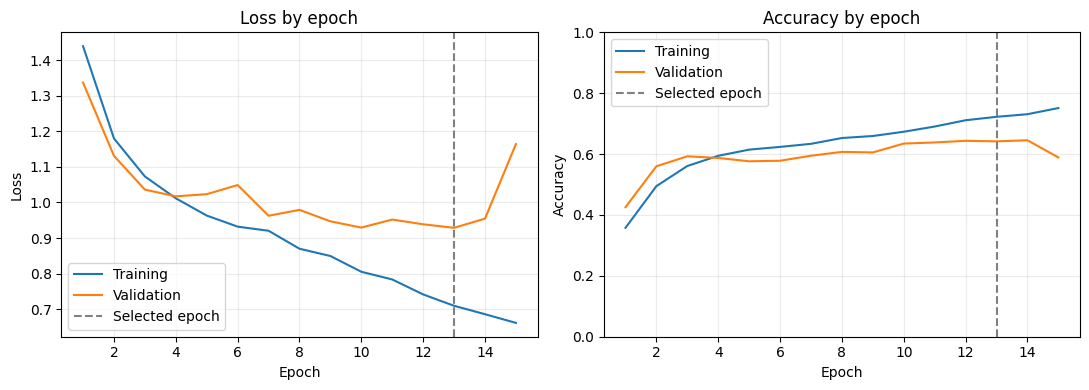

In [29]:
epochs = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ['loss', 'accuracy']):
    ax.plot(epochs, history['train_' + metric], label='Training')
    ax.plot(epochs, history['val_' + metric], label='Validation')
    ax.axvline(best_epoch, color='gray', linestyle='--', label='Selected epoch')
    ax.set(xlabel='Epoch', ylabel=metric.capitalize(), title=metric.capitalize() + ' by epoch')
    ax.legend()
    ax.grid(alpha=0.25)
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()

## 8. Evaluate the selected model on the test set

**Accuracy** is the fraction correct. **Precision** asks how often predictions of a class are right; **recall** asks how many real members of that class we found. **F1** balances precision and recall. **Support** is the number of examples in a class. Macro averages give each class equal weight; weighted averages give more weight to larger classes.

Balanced accuracy averages recall across classes, which helps when class counts differ (there are more dogs than cats in Oxford Pets). We also compare with a trivial model that always predicts the most common *training* class. Confusion-matrix rows are true classes and columns are predictions.

Test loss: 0.9191
Test accuracy: 65.34%
Balanced accuracy: 65.06%
Always predict dandelion baseline: 24.50%
              precision    recall  f1-score   support

       daisy       0.54      0.80      0.64        95
   dandelion       0.68      0.76      0.72       135
       roses       0.60      0.47      0.53        96
  sunflowers       0.83      0.70      0.76       105
      tulips       0.66      0.53      0.59       120

    accuracy                           0.65       551
   macro avg       0.66      0.65      0.65       551
weighted avg       0.67      0.65      0.65       551



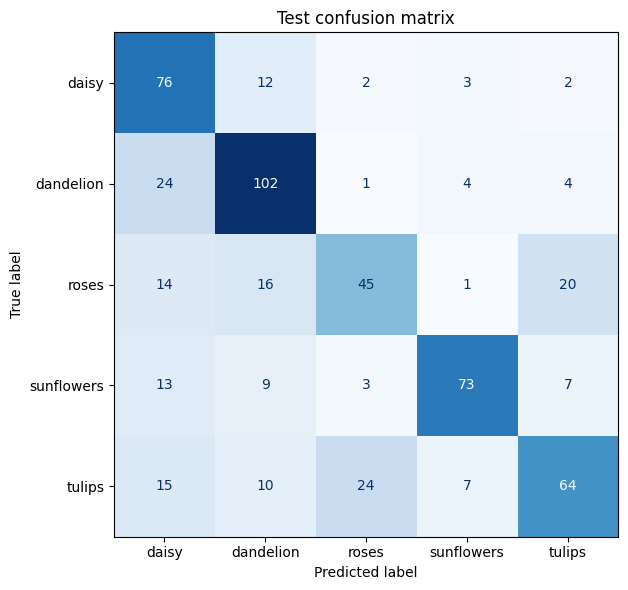

In [30]:
model.eval()
true_labels, predicted_labels, probabilities = [], [], []
test_loss_sum = 0.0
with torch.no_grad():
    for inputs, labels in test_loader:
        logits = model(inputs.to(device))
        test_loss_sum += criterion(logits, labels.to(device)).item() * len(labels)
        # Softmax is useful here to display scores as probabilities.
        # These are model scores, not guarantees or calibrated confidence estimates.
        probabilities.extend(logits.softmax(1).cpu().numpy())
        predicted_labels.extend(logits.argmax(1).cpu().numpy())
        true_labels.extend(labels.numpy())
true_labels = np.asarray(true_labels)
predicted_labels = np.asarray(predicted_labels)
probabilities = np.asarray(probabilities)
test_loss = test_loss_sum / len(true_labels)
test_accuracy = accuracy_score(true_labels, predicted_labels)
balanced_accuracy = balanced_accuracy_score(true_labels, predicted_labels)
majority_class = np.bincount([label for _, label in train_records]).argmax()
baseline_accuracy = np.mean(true_labels == majority_class)
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_accuracy:.2%}')
print(f'Balanced accuracy: {balanced_accuracy:.2%}')
print(f'Always predict {class_names[majority_class]} baseline: {baseline_accuracy:.2%}')
print(classification_report(true_labels, predicted_labels,
      labels=list(range(len(class_names))), target_names=class_names, zero_division=0))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(true_labels, predicted_labels,
    labels=list(range(len(class_names))), display_labels=class_names,
    cmap='Blues', colorbar=False, ax=ax)
ax.set_title('Test confusion matrix')
plt.tight_layout()
plt.show()

## 9. Inspect predictions and mistakes

Visual inspection helps reveal ambiguous photos and recurring errors. The first grid is a reproducible random test sample; the second contains only mistakes. Correct titles are green and incorrect titles are red.

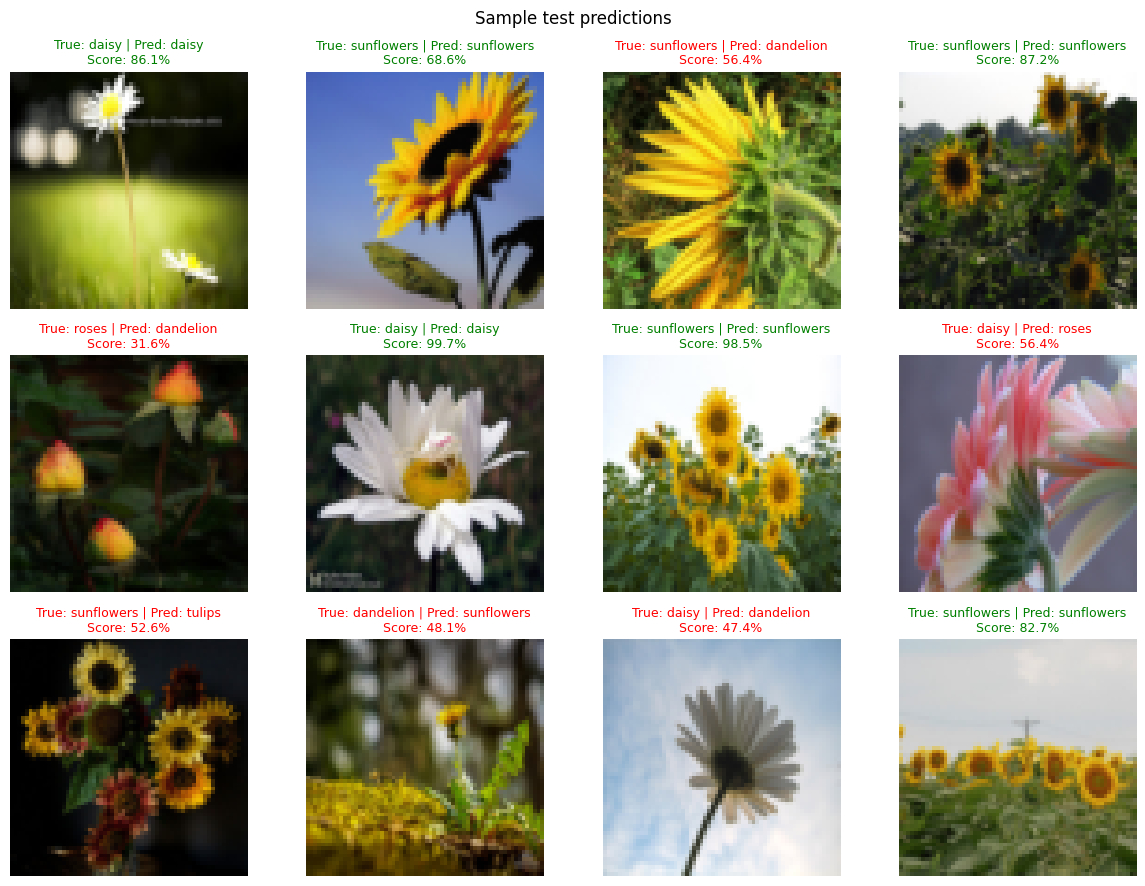

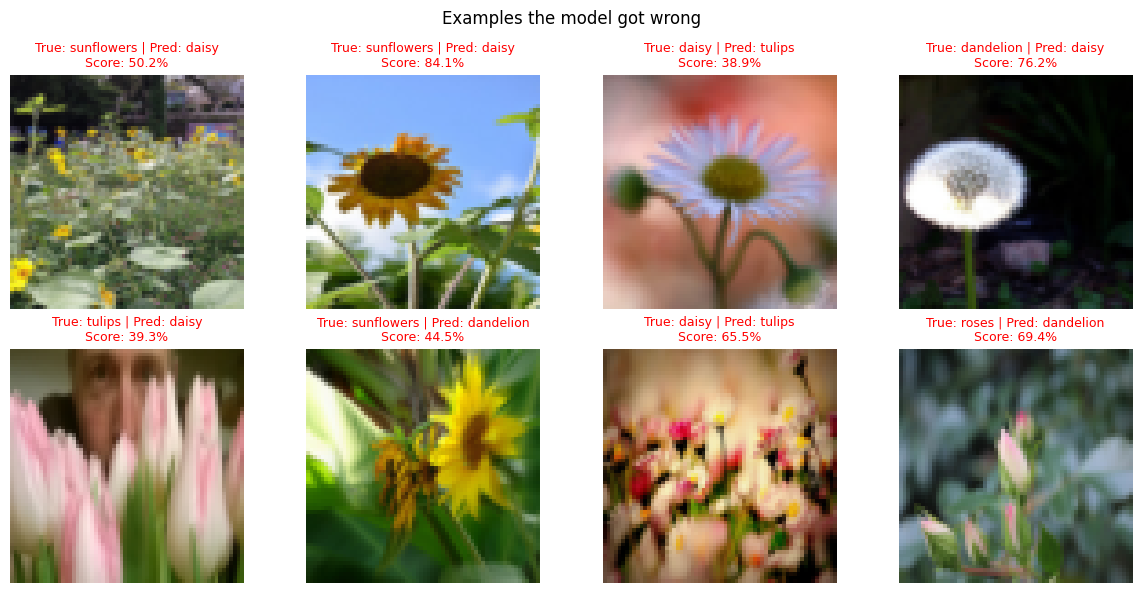

In [31]:
def show_predictions(indices, title):
    if len(indices) == 0:
        print('No mistakes in this test run.')
        return
    fig, axes = plt.subplots((len(indices) + 3) // 4, 4,
                             figsize=(12, 3 * ((len(indices) + 3) // 4)), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, index in zip(axes.flat, indices):
        image, actual = test_dataset[int(index)]
        predicted = predicted_labels[index]
        # Plotting needs H,W,C, whereas PyTorch stores C,H,W.
        ax.imshow(image.permute(1, 2, 0))
        ax.set_title(f'True: {class_names[actual]} | Pred: {class_names[predicted]}\n'
                     f'Score: {probabilities[index, predicted]:.1%}',
                     color='green' if actual == predicted else 'red', fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

rng = np.random.default_rng(SEED)
show_predictions(rng.choice(len(test_dataset), size=12, replace=False), 'Sample test predictions')
errors = np.flatnonzero(true_labels != predicted_labels)
show_predictions(errors[:8], 'Examples the model got wrong')

## 10. Save, reload, and predict one image

We save the weights together with class names and image size so the label mapping is not lost. Reconstruct the same model architecture before loading weights. The example below checks that reloaded weights give the same scores and demonstrates prediction for a single image.

In [32]:
OUTPUT_DIR = Path('outputs') / 'flowers'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
model_path = OUTPUT_DIR / 'basic_cnn.pth'
torch.save({
    'state_dict': {key: value.cpu() for key, value in model.state_dict().items()},
    'class_names': class_names, 'image_size': IMAGE_SIZE, 'best_epoch': best_epoch,
}, model_path)
# Store metrics separately in a human-readable file.
metrics = {'test_loss': test_loss, 'test_accuracy': test_accuracy,
           'balanced_accuracy': balanced_accuracy, 'majority_baseline_accuracy': float(baseline_accuracy),
           'best_epoch': best_epoch, 'history': history}
(OUTPUT_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2))

checkpoint = torch.load(model_path, map_location='cpu', weights_only=True)
assert checkpoint['image_size'] == IMAGE_SIZE
reloaded = BasicCNN(len(checkpoint['class_names'])).to(device)
reloaded.load_state_dict(checkpoint['state_dict'])
reloaded.eval()
one_image, actual = test_dataset[0]
with torch.no_grad():
    batch = one_image.unsqueeze(0).to(device)  # Add batch dimension: (1,3,64,64).
    torch.testing.assert_close(model(batch), reloaded(batch))
    predicted = reloaded(batch).argmax(1).item()
print('Reload verified. Example:', checkpoint['class_names'][predicted],
      '| Actual:', class_names[actual])
print('Saved to:', model_path.resolve())

def predict_image(path):
    with Image.open(path) as image:
        batch = image_transform(image.convert('RGB')).unsqueeze(0).to(device)
    with torch.no_grad():
        scores = reloaded(batch).softmax(1)[0].cpu()
    index = scores.argmax().item()
    return checkpoint['class_names'][index], scores[index].item()

# Replace this with your own photo path to try another image.
print('Single-image prediction:', predict_image(test_records[0][0]))

Reload verified. Example: roses | Actual: roses
Saved to: /Users/rahul/Harvard/CSCIE89-Fall2026/Lectures/Lecture_04/Code/Notebooks/outputs/flowers/basic_cnn.pth
Single-image prediction: ('roses', 0.949927031993866)
